# Projet Smart Groupe 3

#Livrable 1



Livrable: Modélisation graphique et stratégie d’optimisation
Optimisation des tournées de livraison – Task Force CesiCDP ADEME

Ce document présente le problème d’optimisation des tournées de livraison, sa modélisation sous forme de graphe, sa complexité théorique, son modèle mathématique et la stratégie de résolution retenue. Il est rédigé pour qu’un lecteur qui découvre le sujet puisse suivre chaque étape.

## 1. Présentation du problème et modélisation graphique
### 1.1. Le contexte de la mission
L’ADEME (Agence de la transition écologique) cherche à optimiser les tournées de livraison urbaines afin de réduire la durée globale des trajets, l’empreinte carbone (CO2) et les coûts opérationnels.

Le problème étudié est le **CVRPTW** (*Capacitated Vehicle Routing Problem with Time Windows*) : un problème de tournées de véhicules avec capacité, dans lequel chaque client doit être livré dans une **fenêtre horaire** imposée.

### 1.2. Représentation sous forme de graphe
Pour traiter ce problème par ordinateur, on modélise le réseau routier par un **graphe complet pondéré** (orienté ou non) $G = (V, A)$.

**Les sommets (V)**
- Le sommet 0 représente l’entrepôt (dépôt central) d’où partent et où reviennent tous les véhicules.
- Les sommets 1, 2, …, n représentent les clients à livrer.

**Les arcs (A)**
- Ils représentent les liaisons entre les lieux. Chaque arc $(i, j)$ porte un poids $c_{ij}$ : la durée de trajet ou la distance entre le lieu $i$ et le lieu $j$.

**Les contraintes métier**
- **Flotte de véhicules :** $k$ véhicules identiques, tous positionnés au dépôt au départ.
- **Capacité (Q) :** chaque camion a une capacité maximale $Q$ qu’il ne peut pas dépasser.
- **Demande ($q_i$) :** chaque client $i$ demande une quantité de marchandises $q_i$.

**Pour avoir A**

- **Fenêtre de temps $[a_i, b_i]$ :** la livraison chez le client $i$ doit commencer entre $a_i$ (ouverture) et $b_i$ (fermeture). Livrer hors fenêtre est interdit.
- **Attente autorisée :** un camion arrivé trop tôt attend l'ouverture de la fenêtre.
- **Temps de service $s_i$ :** durée de la livraison chez le client $i$.
- **Trafic :** la durée des trajets dépend de la tranche horaire. Ce point sera intégré dans la métaheuristique, avec des durées $c_{ij}$ qui dépendent de l'heure de départ.



**Exemple d’instance**

Pour fixer les idées, la figure 1 montre une petite instance : un dépôt (sommet 0) et 6 clients. Chaque client est annoté de sa demande $q$ et de sa fenêtre de temps $[a, b]$ en minutes. Les traits gris sont les arcs du graphe complet : chacun correspond à une durée de trajet (les valeurs sont données dans la matrice de la section 5). Les camions ont une capacité Q = 12 et la flotte compte K = 2 véhicules.

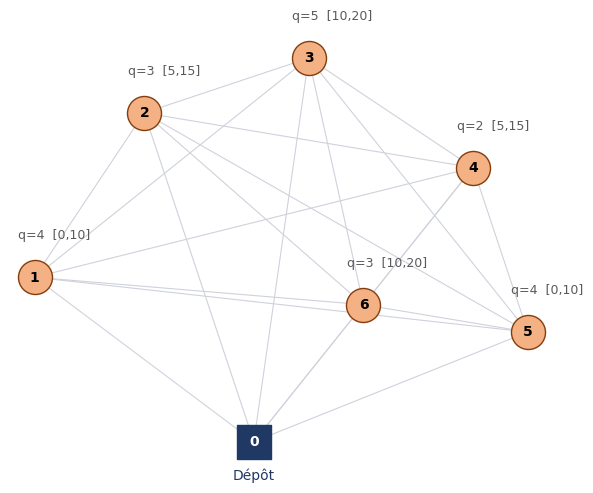

In [ ]:
import matplotlib.pyplot as plt
pos={0:(0,0),1:(-4,3),2:(-2,6),3:(1,7),4:(4,5),5:(5,2),6:(2,2.5)}
q={1:4,2:3,3:5,4:2,5:4,6:3}
tw={1:(0,10),2:(5,15),3:(10,20),4:(5,15),5:(0,10),6:(10,20)}  # fenêtres [a, b] en minutes
def graphe(tournees=None):
    fig,ax=plt.subplots(figsize=(7,6))
    for i in pos:
        for j in pos:
            if i<j: ax.plot(*zip(pos[i],pos[j]),color='#cfd2dc',lw=0.8,zorder=1)
    if tournees:
        for t,col in tournees:
            for a,b in zip(t,t[1:]):
                (x1,y1),(x2,y2)=pos[a],pos[b]
                ax.annotate('',xy=(x2,y2),xytext=(x1,y1),arrowprops=dict(arrowstyle='-|>',color=col,lw=2,shrinkA=12,shrinkB=12),zorder=2)
                d=((x1-x2)**2+(y1-y2)**2)**.5
                ax.text((x1+x2)/2,(y1+y2)/2,f'{d:.1f}',color=col,fontweight='bold',fontsize=9)
    ax.scatter(*pos[0],marker='s',s=600,color='#1f3864',zorder=3)
    ax.text(*pos[0],'0',color='white',ha='center',va='center',fontweight='bold',zorder=4)
    ax.text(pos[0][0],pos[0][1]-0.7,'Dépôt',ha='center',color='#1f3864')
    for i in q:
        ax.scatter(*pos[i],s=600,color='#f4b183',edgecolors='#843c0c',zorder=3)
        ax.text(*pos[i],str(i),ha='center',va='center',fontweight='bold',zorder=4)
        ax.text(pos[i][0]-0.3,pos[i][1]+0.7,f'q={q[i]}  [{tw[i][0]},{tw[i][1]}]',color='#595959',fontsize=9)
    if tournees:
        for t,col in tournees: ax.plot([],[],color=col,lw=2,label=t[2] if False else '')
        ax.legend(['Tournée 1 : 0 → 1 → 2 → 3 → 0','Tournée 2 : 0 → 5 → 4 → 6 → 0'],loc='lower center',bbox_to_anchor=(0.5,-0.15),frameon=False)
    ax.axis('off'); ax.set_aspect('equal'); plt.show()
graphe()

*Figure 1 – Graphe complet d’une instance à 6 clients (sommets, demandes, arcs)*

## 2. Classification et complexité théorique
### 2.1. À quelle classe appartient ce problème ?
Le problème est **NP-difficile** dans sa version d'optimisation et **NP-complet** dans sa version de décision.

**Version de décision (oui / non) : NP-complet**

*Question :* existe-t-il un ensemble de tournées respectant la capacité des camions et les fenêtres de temps, dont la durée totale est inférieure ou égale à T minutes ?
- **Appartenance à NP :** si quelqu'un nous fournit une solution (un « certificat »), on vérifie sa validité en temps polynomial, de l'ordre de O(n) : chaque client est visité une seule fois, les capacités sont respectées, les heures de livraison tombent dans les fenêtres et la durée est inférieure ou égale à T.
- **NP-difficulté : réduction polynomiale depuis le TSP.** Le TSP est NP-complet (par réduction depuis le cycle hamiltonien, Karp 1972). À partir d'une instance du TSP ($n$ villes, distances $d$, borne $T$), on construit en $O(n^2)$ :
  - dépôt = ville 1, clients = les autres villes, $c_{ij} = d_{ij}$ ;
  - $K = 1$ camion, $q_i = 1$, $Q = n$ ;
  - fenêtres sans effet : $a_i = 0$, $b_i = +\infty$, $s_i = 0$.

  Une tournée unique qui visite tous les clients et revient au dépôt est exactement un cycle hamiltonien de même durée. Il existe donc un tour $\le T$ **si et seulement si** il existe une tournée $\le T$. Le CVRPTW est donc NP-complet.
- **Les fenêtres de temps durcissent encore le problème :** avec des fenêtres, trouver une simple solution réalisable est déjà NP-complet (Savelsbergh, 1985).

**Version d'optimisation : NP-difficile**

*Question :* quelle est la *meilleure* combinaison de tournées, celle qui minimise la durée totale ? Trouver la meilleure solution est au moins aussi difficile que de répondre à la version de décision.

### 2.2. L'explosion combinatoire
Pour n clients, le nombre de façons d'ordonner les visites et de les répartir entre les camions croît de manière factorielle, donc plus vite qu'une exponentielle.
- **10 clients :** déjà $10! \approx 3{,}6$ millions d'ordres de visite.
- **30 clients :** $30! \approx 2{,}7 \times 10^{32}$ combinaisons. Un ordinateur très puissant mettrait des milliards d'années à tout tester par force brute.

## 3. Modélisation mathématique (PLNE)
Pour exprimer le problème sous une forme exploitable par un solveur, on utilise la programmation linéaire en nombres entiers (PLNE). Le modèle repose sur trois composants : les variables de décision, la fonction objectif et les contraintes.

### 3.1. Les variables de décision
Ce sont les inconnues que le solveur doit déterminer.
1. Variable binaire de trajet (vaut 1 si le véhicule k va directement du lieu i au lieu j, avec $i \neq j$, 0 sinon) :
$$x_{ijk} \in \{0, 1\}$$
2. Variable de charge auxiliaire $u_i \geq 0$ : elle suit la charge cumulée du camion au fil de la tournée et permet d'éliminer les « sous-tours » (des boucles isolées qui ne passeraient pas par le dépôt).
3. Variable de temps $T_{ik} \geq 0$ : heure à laquelle le camion $k$ commence la livraison chez le client $i$.

### 3.2. La fonction objectif
L'objectif est de minimiser le temps total de parcours de l'ensemble de la flotte :
$$\min Z = \sum_{k=1}^{K} \sum_{i=0}^{n} \sum_{j=0}^{n} c_{ij} \cdot x_{ijk}$$
où $c_{ij}$ est le coût (la durée) du trajet entre i et j.

### 3.3. Les contraintes
Ce sont les règles que le modèle doit respecter.

**1. Visite unique de chaque client**

Chaque client j (hors dépôt) est visité exactement une fois, par un seul véhicule :
$$\sum_{k=1}^{K} \sum_{i=0, i\neq j}^{n} x_{ijk} = 1 \quad \forall j \in \{1, \dots, n\}$$

**2. Flux et continuité des tournées**

Si un camion k arrive chez un client j, il doit obligatoirement en repartir :
$$\sum_{i=0, i\neq j}^{n} x_{ijk} - \sum_{l=0, l\neq j}^{n} x_{jlk} = 0 \quad \forall j \in \{0, \dots, n\}, \forall k$$

**3. Capacité maximale du véhicule**

La somme des demandes $q_j$ des clients livrés par le camion k ne doit pas dépasser sa capacité Q :
$$\sum_{i=0}^{n} \sum_{j=1, j\neq i}^{n} q_j \cdot x_{ijk} \leq Q \quad \forall k \in \{1, \dots, K\}$$


**4. Élimination des sous-tours (MTZ adapté)**

Pour empêcher la formation de cycles fermés indépendants du dépôt :
$$u_i - u_j + Q \cdot x_{ijk} \leq Q - q_j \quad \forall i, j \neq 0, i \neq j, \forall k$$
$$q_i \leq u_i \leq Q \quad \forall i \in \{1, \dots, n\}$$
x
ij
​
  (L'action) : Variable binaire.   
x
ij
​
 =1 si le camion va directement de la ville
i à la ville
j.   
x
ij
​
 =0 sinon.   
u
i
​
  et
u
j
​
  (Le compteur de charge) : Représentent le cumul de la charge de marchandise dans le camion au moment où il arrive à la ville
i (ou
j).   

q
j
​
  (La commande) : Quantité de marchandise demandée par le client
j.   
Q (La capacité maximale) : Contenance maximale du camion
 Pourquoi l'écrire sous cette forme complexe avec
+Q⋅x
ij
​
  ?
En programmation linéaire (PLNE), un solveur mathématique (comme PuLP ou Cplex) ne comprend pas les instructions conditionnelles classiques comme :

« SI
x
ij
​
 =1 ALORS
u
j
​
 ≥u
i
​
 +q
j
​
  SINON rien »

Le terme
+Q⋅x
ij
​
  est une astuce mathématique (souvent appelée technique du Grand M ou formulation Miller-Tucker-Zemlin) qui permet d'activer ou de désactiver la contrainte selon que la variable binaire
x
ij
​
  vaut
1 ou
0 :   

Si
x
ij
​
 =1, le terme
+Q s'annule avec le
Q du côté droit, ce qui active la contrainte :
u
j
​
 ≥u
i
​
 +q
j
​
 .

Si
x
ij
​
 =0, le terme
+Q disparaît à gauche, ce qui laisse
+Q à droite et désactive la contrainte (elle devient inactive/triviale).

**5. Départ du dépôt**

Chaque camion quitte le dépôt au plus une fois :
$$\sum_{j=1}^{n} x_{0jk} \leq 1 \quad \forall k$$

**6. Enchaînement des horaires**

Si le camion k va de i à j, la livraison en j commence au plus tôt après la fin de la livraison en i plus le temps de trajet :
$$T_{ik} + s_i + c_{ij} - T_{jk} \leq M\,(1 - x_{ijk}) \quad \forall i, j,\ i \neq j,\ j \neq 0,\ \forall k$$
M est un grand nombre : si $x_{ijk} = 0$, la contrainte est désactivée. L'inégalité autorise l'attente, car $T_{jk}$ peut être plus tard que l'heure d'arrivée.

**7. Fenêtres de temps**

La livraison chez le client i commence entre son ouverture $a_i$ et sa fermeture $b_i$ :
$$a_i \leq T_{ik} \leq b_i \quad \forall i,\ \forall k$$


**rappel: contre exemple**

## 4. Méthode proposée pour trouver la meilleure solution
Face à la complexité NP-difficile, nous adoptons une approche à deux niveaux, selon la taille de l’instance.

| Taille | Petite instance (n < 20) | Grande instance (n ≥ 20) |
|---|---|---|
| **Méthode** | Méthode exacte (PLNE avec solveur) | Métaheuristique (recherche locale, ALNS) |
| **Résultat** | Optimum absolu | Excellente solution, obtenue très vite |

### 4.1. Petites instances : méthode exacte (PLNE / PuLP)
- **Outil :** programmation linéaire en nombres entiers via un solveur (par exemple CBC avec PuLP sous Python).
- **Rôle :** résoudre le modèle mathématique formel pour obtenir la solution optimale absolue (Gap = 0 %).
- **Limite :** utilisable uniquement sur de petits réseaux (moins de 20 clients), car le temps de calcul explose au-delà.

### 4.2. Grandes instances : métaheuristiques
Pour obtenir des résultats rapides et de qualité industrielle sur des cartes de 50 à 2 000 clients, nous déployons une métaheuristique, par exemple l’ALNS (*Adaptive Large Neighborhood Search*), le recuit simulé ou la recherche tabou.

**Déroulement de l’algorithme**
1. **Pré-calcul des distances (indispensable).** Avant toute optimisation, on calcule une matrice des distances ou durées entre chaque paire de sommets. Cela évite de recalculer inutilement les plus courts chemins dans la boucle.
2. **Solution initiale gloutonne.** On génère rapidement une première solution réalisable avec une heuristique simple (plus proche voisin, méthode des balayages ou des savings).
3. **Boucle d’amélioration (intensification et diversification).** Elle combine deux mécanismes :
   - **Destruction / reconstruction (ALNS) :** on retire une partie des clients des tournées, puis on les réinsère au meilleur endroit.
   - **Recherche locale (2-opt, Relocate, Swap) :** on décroise les trajets pour raccourcir la distance.
4. **Indicateur de performance : le Gap.** On mesure la qualité de la métaheuristique par rapport aux solutions optimales connues (VRPLIB) :
$$\text{Gap} = 100 \times \frac{\text{Coût de notre solution} - \text{Coût optimal}}{\text{Coût optimal}}$$

Objectif visé : entrer dans la zone verte (Gap ≤ 7 %).

## 5. Application sur l'instance d'exemple
Cette section déroule la méthode sur l'instance de la figure 1, pour montrer concrètement ce que le modèle cherche à produire.

### 5.1. Données de l'instance
| Élément | Valeur |
|---|---|
| Dépôt | Sommet 0 |
| Clients | Sommets 1 à 6 |
| Demandes q | q1 = 4, q2 = 3, q3 = 5, q4 = 2, q5 = 4, q6 = 3 (total : 21) |
| Capacité Q | 12 par camion |
| Flotte K | 2 véhicules (21 > 12, donc un seul camion ne suffit pas, et 21 ≤ 2 × 12) |
| Temps de service s | 1 min chez chaque client |
| Départ du dépôt | t = 0 |

**Fenêtres de temps (en minutes)**

| Client | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| $[a_i, b_i]$ | [0, 10] | [5, 15] | [10, 20] | [5, 15] | [0, 10] | [10, 20] |

### 5.2. Matrice des durées de trajet
C'est le pré-calcul indispensable décrit en 4.2 : la durée $c_{ij}$ entre chaque paire de sommets, calculée une fois pour toutes (ici la distance euclidienne, arrondie à 0,1 minute).

| | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| **0** | 0.0 | 5.0 | 6.3 | 7.1 | 6.4 | 5.4 | 3.2 |
| **1** | 5.0 | 0.0 | 3.6 | 6.4 | 8.2 | 9.1 | 6.0 |
| **2** | 6.3 | 3.6 | 0.0 | 3.2 | 6.1 | 8.1 | 5.3 |
| **3** | 7.1 | 6.4 | 3.2 | 0.0 | 3.6 | 6.4 | 4.6 |
| **4** | 6.4 | 8.2 | 6.1 | 3.6 | 0.0 | 3.2 | 3.2 |
| **5** | 5.4 | 9.1 | 8.1 | 6.4 | 3.2 | 0.0 | 3.0 |
| **6** | 3.2 | 6.0 | 5.3 | 4.6 | 3.2 | 3.0 | 0.0 |

**Comment est obtenue la matrice ?** Chaque sommet a des coordonnées $(x, y)$ (celles de la figure 1). La durée entre deux sommets est la **distance euclidienne** (théorème de Pythagore), arrondie à 0,1 minute :

$$c_{ij} = \sqrt{(x_i - x_j)^2 + (y_i - y_j)^2}$$

| Sommet | 0 (dépôt) | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| $(x, y)$ | (0, 0) | (−4, 3) | (−2, 6) | (1, 7) | (4, 5) | (5, 2) | (2, 2.5) |

*Exemple 1 : du dépôt 0 au client 1*, avec 0 = (0, 0) et 1 = (−4, 3) :
$$c_{01} = \sqrt{(0-(-4))^2 + (0-3)^2} = \sqrt{16 + 9} = \sqrt{25} = 5{,}0$$

*Exemple 2 : du client 1 au client 2*, avec 1 = (−4, 3) et 2 = (−2, 6) :
$$c_{12} = \sqrt{(-4-(-2))^2 + (3-6)^2} = \sqrt{4 + 9} = \sqrt{13} \approx 3{,}6$$

La matrice est symétrique ($c_{ij} = c_{ji}$) et sa diagonale est nulle. Dans un cas réel, on remplacerait la distance euclidienne par le plus court chemin sur le réseau routier (algorithme de Dijkstra), calculé une seule fois avant l'optimisation.

### 5.3. Solution optimale
La figure 2 montre la meilleure solution : deux tournées qui partent du dépôt et y reviennent, en respectant la capacité et les fenêtres de temps.

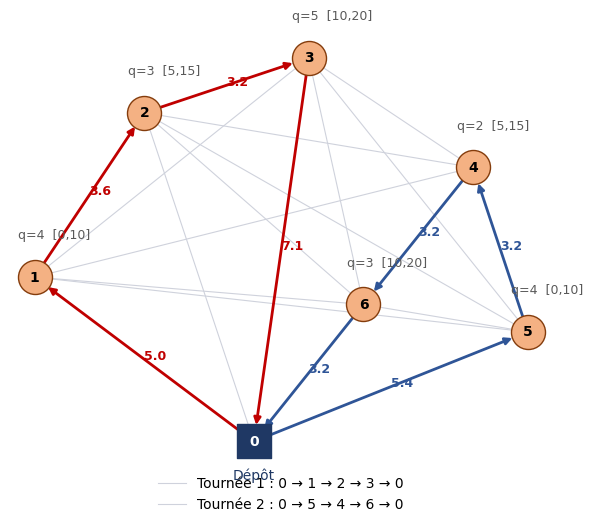

In [ ]:
graphe([([0,1,2,3,0],'#c00000'),([0,5,4,6,0],'#2f5597')])

*Figure 2 – Solution optimale : deux tournées (rouge et bleu) et durées des arcs utilisés*

| Tournée | Parcours | Charge / Q | Durée |
|---|---|---|---|
| **Tournée 1** | 0 → 1 → 2 → 3 → 0 | 12 / 12 | 18.9 min |
| **Tournée 2** | 0 → 5 → 4 → 6 → 0 | 9 / 12 | 15.0 min |
| **Total** | | | 33.9 min |

**Lecture :** la tournée 1 est pleine (4 + 3 + 5 = 12) et la tournée 2 n'est chargée qu'à 9 sur 12. Chaque client est bien visité une seule fois, aucune capacité n'est dépassée et chaque livraison commence dans sa fenêtre (vérification dans la cellule suivante) : ce sont exactement les contraintes du modèle. Comme l'instance est petite, cette solution a été confirmée optimale en énumérant toutes les répartitions possibles des clients entre les deux camions et tous les ordres de visite. C'est l'équivalent de ce que fait le solveur PLNE de la section 4.1. Sur une grande instance, cette énumération devient impossible, d'où le recours aux métaheuristiques.

*Remarque :* les coordonnées des sommets et les fenêtres de temps sont choisies pour l'illustration. Elles ne proviennent pas des données réelles de l'ADEME.

In [ ]:
# Vérification des tournées : capacité, horaires (avec attente) et fenêtres
c = [[0.0, 5.0, 6.3, 7.1, 6.4, 5.4, 3.2], [5.0, 0.0, 3.6, 6.4, 8.2, 9.1, 6.0],
     [6.3, 3.6, 0.0, 3.2, 6.1, 8.1, 5.3], [7.1, 6.4, 3.2, 0.0, 3.6, 6.4, 4.6],
     [6.4, 8.2, 6.1, 3.6, 0.0, 3.2, 3.2], [5.4, 9.1, 8.1, 6.4, 3.2, 0.0, 3.0],
     [3.2, 6.0, 5.3, 4.6, 3.2, 3.0, 0.0]]
s, Q = 1, 12


def verifier_tournee(tournee):
    charge, t, prec, duree, ok = sum(q[i] for i in tournee), 0.0, 0, 0.0, True
    for i in tournee:
        arrivee = t + (s if prec else 0) + c[prec][i]
        duree += c[prec][i]
        t = max(arrivee, tw[i][0])              # attente si arrivée avant l'ouverture
        ok &= t <= tw[i][1]
        print(f"   client {i} : arrivée {arrivee:4.1f}, début {t:4.1f}, fenêtre {list(tw[i])} "
              f"{'OK' if t <= tw[i][1] else 'VIOLÉE'}")
        prec = i
    duree += c[prec][0]
    print(f"   charge {charge}/{Q}, durée {duree:.1f} min, réalisable : {ok and charge <= Q}\n")
    return duree


total = 0
for nom, tour in [("Tournée 1", [1, 2, 3]), ("Tournée 2", [5, 4, 6])]:
    print(nom, ": 0 →", " → ".join(map(str, tour)), "→ 0")
    total += verifier_tournee(tour)
print(f"Durée totale : {total:.1f} min")

Tournée 1 : 0 → 1 → 2 → 3 → 0
   client 1 : arrivée  5.0, début  5.0, fenêtre [0, 10] OK
   client 2 : arrivée  9.6, début  9.6, fenêtre [5, 15] OK
   client 3 : arrivée 13.8, début 13.8, fenêtre [10, 20] OK
   charge 12/12, durée 18.9 min, réalisable : True

Tournée 2 : 0 → 5 → 4 → 6 → 0
   client 5 : arrivée  5.4, début  5.4, fenêtre [0, 10] OK
   client 4 : arrivée  9.6, début  9.6, fenêtre [5, 15] OK
   client 6 : arrivée 13.8, début 13.8, fenêtre [10, 20] OK
   charge 9/12, durée 15.0 min, réalisable : True

Durée totale : 33.9 min


## 6. Conversion du PNL en Pulp

In [ ]:
import math
import pulp

# 1. DONNÉES (les mêmes que dans le graphe)
pos = {0: (0, 0), 1: (-4, 3), 2: (-2, 6), 3: (1, 7), 4: (4, 5), 5: (5, 2), 6: (2, 2.5)}  # coordonnées
q = {1: 4, 2: 3, 3: 5, 4: 2, 5: 4, 6: 3}                                                  # demandes
tw = {1: (0, 10), 2: (5, 15), 3: (10, 20), 4: (5, 15), 5: (0, 10), 6: (10, 20)}         # fenêtres [a, b]

V = list(pos)                       # tous les sommets : 0 = dépôt, 1..n = clients
N = [i for i in V if i != 0]        # uniquement les clients
K = range(2)                        # les camions (ici 2 : camion 0 et camion 1)
Q = 12                              # capacité de chaque camion
s = 1                               # temps de service chez chaque client (minutes)
M = 100                             # « grand nombre » de la contrainte 6

# Matrice des durées c_ij = distance euclidienne entre i et j (Pythagore)
c = {(i, j): round(math.dist(pos[i], pos[j]), 1) for i in V for j in V if i != j}

# 2. LE PROBLÈME : on cherche le MINIMUM
prob = pulp.LpProblem("CVRPTW", pulp.LpMinimize)

# 3. VARIABLES DE DÉCISION
# x[i, j, k] = 1 si le camion k va directement de i à j, 0 sinon (binaire)
x = {(i, j, k): pulp.LpVariable(f"x_{i}_{j}_{k}", cat="Binary") for (i, j) in c for k in K}

# u[i] = charge cumulée du camion après le client i (sert à MTZ)
u = {i: pulp.LpVariable(f"u_{i}", lowBound=0) for i in N}

# T[i, k] = heure à laquelle le camion k commence la livraison chez i
T = {(i, k): pulp.LpVariable(f"T_{i}_{k}", lowBound=0) for i in V for k in K}

# 4. FONCTION OBJECTIF
prob += pulp.lpSum(c[i, j] * x[i, j, k] for (i, j) in c for k in K)

# 5. CONTRAINTES

# --- Contrainte 1 : visite unique de chaque client ---
for j in N:
    prob += pulp.lpSum(x[i, j, k] for i in V if i != j for k in K) == 1

# --- Contrainte 2 : flux et continuité des tournées ---
for k in K:
    for j in V:
        prob += (pulp.lpSum(x[i, j, k] for i in V if i != j)
                 == pulp.lpSum(x[j, l, k] for l in V if l != j))

# --- Contrainte 3 : capacité maximale du véhicule ---

for k in K:
    prob += pulp.lpSum(q[j] * x[i, j, k] for (i, j) in c if j != 0) <= Q

# --- Contrainte 4 : élimination des sous-tours (MTZ) ---

for i in N:
    for j in N:
        if i != j:
            for k in K:
                prob += u[i] - u[j] + Q * x[i, j, k] <= Q - q[j]

# Bornes de MTZ : q_i ≤ u_i ≤ Q   ∀ i ∈ N
# → la charge cumulée est au moins la demande du client et jamais plus que la capacité
for i in N:
    prob += u[i] >= q[i]
    prob += u[i] <= Q

# --- Contrainte 5 : départ du dépôt ---
for k in K:
    prob += pulp.lpSum(x[0, j, k] for j in N) <= 1

# Heure de départ : T_0k = 0   ∀ k
# → tous les camions partent du dépôt à t = 0
for k in K:
    prob += T[0, k] == 0

# --- Contrainte 6 : enchaînement des horaires ---
for (i, j) in c:
    if j != 0:
        for k in K:
            prob += T[i, k] + (s if i != 0 else 0) + c[i, j] - T[j, k] <= M * (1 - x[i, j, k])

# --- Contrainte 7 : fenêtres de temps ---
for i in N:
    for k in K:
        prob += T[i, k] >= tw[i][0]
        prob += T[i, k] <= tw[i][1]

# 6. RÉSOLUTION (solveur CBC, livré avec PuLP)
prob.solve(pulp.PULP_CBC_CMD(msg=False))
print("Statut :", pulp.LpStatus[prob.status])
print(f"Durée totale optimale : {pulp.value(prob.objective):.1f} min\n")

# 7. LECTURE DE LA SOLUTION
for k in K:
    tournee, i = [0], 0
    while True:
        i = next((j for j in V if j != i and x[i, j, k].value() > 0.5), None)
        if i is None or i == 0:
            break
        tournee.append(i)
    if len(tournee) > 1:
        print(f"Camion {k + 1} : {' → '.join(map(str, tournee))} → 0")

Statut : Optimal
Durée totale optimale : 33.9 min

Camion 1 : 0 → 1 → 2 → 3 → 0
Camion 2 : 0 → 5 → 4 → 6 → 0


## Résumé
| Notion | Définition simple |
|---|---|
| **Objectif** | Minimiser le temps total des camions pour réduire la pollution et les coûts. |
| **Graphe** | Une carte où les lieux sont des points (sommets) et les routes des traits (arcs) pondérés par un temps de trajet. |
| **NP-difficile** | Problème tellement vaste qu’il est impossible de tester toutes les solutions une par une sur de grandes cartes. |
| **PLNE (exact)** | Équations mathématiques strictes qui donnent la meilleure réponse absolue, mais lentes sur de grands réseaux. |
| **Métaheuristique** | Stratégie d’exploration « intelligente » des trajets qui donne une très bonne solution en quelques secondes. |

# Livrable 2

## 1. GRASP + Recherche Tabou : le code

On reprend la logique du workshop (sac à dos) et on l'adapte au CVRPTW :

| Workshop (sac à dos) | Projet (CVRPTW) |
|---|---|
| solution = tuple de booléens | solution = liste de tournées `[[1, 2, 3], [5, 4, 6]]` (dépôt implicite) |
| `poids_contenu(sac) <= capacite` | `tournee_valide(t)` : capacité + fenêtres de temps (attente autorisée) |
| `random_solution()` | `grasp_construction(alpha)` : glouton randomisé avec une RCL |
| voisin = inverser un objet | voisin = **relocate** (déplacer un client) ou **swap** (échanger deux clients) |
| liste tabou de solutions | liste tabou de **clients déplacés** + critère d'aspiration |
| multi-start | `grasp_tabou()` : on répète construction + tabou et on garde la meilleure |

La cellule ci-dessous écrit le fichier `grasp_tabou_cvrptw.py` (avec `%%writefile`) pour qu'on puisse l'importer ensuite avec `import grasp_tabou_cvrptw as g`.

In [ ]:
%%writefile grasp_tabou_cvrptw.py
"""
Livrable 2 - GRASP + Recherche Tabou pour le CVRPTW
====================================================

Idée générale (même logique que le Workshop du sac à dos) :
  - une SOLUTION = une liste de tournées, chaque tournée = une liste de clients
    (le dépôt 0 n'est pas écrit, il est implicite au début et à la fin)
        ex : [[1, 2, 3], [5, 4, 6]]  <=>  0→1→2→3→0  et  0→5→4→6→0
  - GRASP  = construction gloutonne RANDOMISÉE (remplace random_solution())
  - TABOU  = on va au meilleur voisin non tabou, même s'il est moins bon
  - MULTI-START = on répète GRASP + Tabou plusieurs fois et on garde le meilleur

Fonctionne pour :
  - le CVRP   (si pas de fenêtres : a = 0, b = très grand, service = 0)
  - le CVRPTW (fenêtres de temps [a_i, b_i], attente autorisée)
"""

import math
import random
import time
from collections import deque

# Active / désactive le mouvement 2-opt dans le voisinage.
# Sur nos tests (100 clients aléatoires) il n'améliorait pas le coût :
# on le laisse en OPTION pour le comparer sur les instances VRPLIB.
UTILISER_2OPT = False


# =============================================================================
# 1. DONNÉES DE L'INSTANCE
# =============================================================================
# On stocke tout dans des variables globales, comme dans le workshop


def charger_instance(coords, demandes, Q_cap, fenetres=None, service=None):
    """
    Prépare l'instance.
    coords   : liste de (x, y), indice 0 = dépôt
    demandes : liste des demandes q_i (q_0 = 0)
    Q_cap    : capacité d'un camion
    fenetres : liste de (a_i, b_i)  (None => pas de fenêtres = CVRP)
    service  : liste des temps de service s_i (None => 0 partout)
    """
    global n, q, Q, tw, s, dist

    n = len(coords)                      # nombre de sommets (dépôt compris)
    q = list(demandes)
    Q = Q_cap
    tw = list(fenetres) if fenetres is not None else [(0, float("inf"))] * n
    s = list(service) if service is not None else [0] * n

    # PRÉ-CALCUL de la matrice des distances (indispensable, cf. livrable 1)
    # Pour des milliers de clients, numpy est conseillé (voir plus bas).
    dist = [[math.dist(coords[i], coords[j]) for j in range(n)] for i in range(n)]


# =============================================================================
# 2. FONCTIONS DE BASE (équivalent de poids_contenu / valeur_contenu)
# =============================================================================

def cout_tournee(tournee):
    """Distance totale d'une tournée (dépôt → clients → dépôt)."""
    if not tournee:
        return 0.0
    c = dist[0][tournee[0]] + dist[tournee[-1]][0]
    for i in range(len(tournee) - 1):
        c += dist[tournee[i]][tournee[i + 1]]
    return c


def cout_solution(solution):
    """Coût total = somme des coûts des tournées (fonction objectif Z)."""
    return sum(cout_tournee(t) for t in solution)


def tournee_valide(tournee):
    """
    Vérifie capacité ET fenêtres de temps (avec attente autorisée).
    C'est l'équivalent de 'poids_contenu(sac) <= capacite' du workshop.
    """
    # 1) Capacité
    if sum(q[i] for i in tournee) > Q:
        return False

    # 2) Fenêtres de temps : on simule le trajet du camion
    t = 0.0          # heure de départ du dépôt
    prec = 0         # on part du dépôt
    for i in tournee:
        t = t + s[prec] + dist[prec][i]   # arrivée chez i
        t = max(t, tw[i][0])              # attente si on arrive trop tôt
        if t > tw[i][1]:                  # trop tard => interdit
            return False
        prec = i

    # 3) Retour au dépôt avant sa fermeture
    t = t + s[prec] + dist[prec][0]
    return t <= tw[0][1]


# =============================================================================
# 3. CONSTRUCTION GRASP (remplace random_solution() du workshop)
# =============================================================================

def grasp_construction(alpha=0.3):
    """
    Construit une solution tournée par tournée.
    À chaque étape :
      1. on liste les clients qu'on peut ajouter à la fin de la tournée courante
         sans violer capacité / fenêtres
      2. on les classe par 'distance' depuis le dernier client
      3. RCL (Restricted Candidate List) : on garde les meilleurs
         (ceux dont le score <= min + alpha * (max - min))
      4. on en tire un AU HASARD dans la RCL  => c'est le côté "randomisé"
    alpha = 0 : glouton pur (plus proche voisin)  /  alpha = 1 : aléatoire pur
    """
    non_visites = set(range(1, n))
    solution = []

    while non_visites:
        tournee = []
        while True:
            dernier = tournee[-1] if tournee else 0

            # 1. candidats réalisables
            candidats = [j for j in non_visites if tournee_valide(tournee + [j])]
            if not candidats:
                break  # plus rien ne rentre => on ferme la tournée

            # 2. score = distance + un peu d'urgence (fermeture de fenêtre)
            #    => on privilégie les clients proches ET pressés
            score = {j: dist[dernier][j] + 0.1 * tw[j][1] if tw[j][1] != float("inf")
                     else dist[dernier][j] for j in candidats}

            # 3. RCL
            smin, smax = min(score.values()), max(score.values())
            seuil = smin + alpha * (smax - smin)
            rcl = [j for j in candidats if score[j] <= seuil]

            # 4. choix aléatoire dans la RCL
            choisi = random.choice(rcl)
            tournee.append(choisi)
            non_visites.remove(choisi)

        if not tournee:
            # un client ne rentre même pas seul dans un camion : instance infaisable
            raise ValueError(f"Clients impossibles à servir : {non_visites}")
        solution.append(tournee)

    return solution


# =============================================================================
# 4. VOISINAGE (équivalent de voisinage(sac) du workshop)
# =============================================================================
# Workshop : un voisin = on inverse UN objet du sac.
# Ici      : un voisin = on DÉPLACE UN client (relocate)
#            ou on ÉCHANGE deux clients (swap)
#            ou on INVERSE un morceau de tournée (2-opt).
#
# ACCÉLÉRATION (version 2) :
#   Avant, pour chaque voisin on recopiait TOUTE la solution puis on
#   recalculait TOUT le coût  => O(n) par voisin, beaucoup trop lent.
#   Maintenant, un voisin n'est plus une solution complète mais un MOUVEMENT
#   (quelques indices). Son coût se calcule par DIFFÉRENCE (delta) avec
#   seulement 3 ou 4 distances => O(1) par voisin.
#   On ne vérifie la validité (capacité / fenêtres) QUE si le mouvement est
#   intéressant, et on ne construit la nouvelle solution QUE pour le
#   mouvement finalement choisi.

def autour(tournee, p):
    """Renvoie (précédent, suivant) du client en position p (0 = dépôt)."""
    prec = tournee[p - 1] if p > 0 else 0
    suiv = tournee[p + 1] if p < len(tournee) - 1 else 0
    return prec, suiv


def voisinage(solution, taille_echantillon=None):
    """
    Générateur de mouvements : (delta, mouvement).
      delta     = nouveau coût - coût actuel (négatif = amélioration)
      mouvement = ("relocate" | "swap" | "2opt", r1, p1, r2, p2)
    ATTENTION : la validité n'est PAS vérifiée ici (voir mouvement_valide).
    taille_echantillon : pour les grandes instances, on ne teste qu'un
    échantillon aléatoire de clients (sinon le voisinage est énorme).
    """
    tous_clients = [(r, p) for r, t in enumerate(solution) for p in range(len(t))]
    if taille_echantillon and len(tous_clients) > taille_echantillon:
        tous_clients = random.sample(tous_clients, taille_echantillon)

    for (r1, p1) in tous_clients:
        t1 = solution[r1]
        c = t1[p1]
        a, b = autour(t1, p1)
        # gain obtenu en retirant c :  a -> c -> b  devient  a -> b
        delta_retrait = dist[a][b] - dist[a][c] - dist[c][b]

        # ----- RELOCATE : on retire c et on le remet entre x et y -----
        for r2 in range(len(solution) + 1):          # +1 = ouvrir un nouveau camion
            if r2 == len(solution):
                if len(t1) > 1:                      # nouveau camion : 0 -> c -> 0
                    yield delta_retrait + 2 * dist[0][c], ("relocate", r1, p1, r2, 0)
                continue
            t2 = solution[r2]
            for p2 in range(len(t2) + 1):            # insertion AVANT la position p2
                if r1 == r2 and (p2 == p1 or p2 == p1 + 1):
                    continue                         # même position
                x = t2[p2 - 1] if p2 > 0 else 0
                y = t2[p2] if p2 < len(t2) else 0
                if r1 == r2:                         # même tournée : c n'est plus là
                    if x == c:
                        x = a
                    if y == c:
                        y = b
                # coût ajouté en insérant c :  x -> y  devient  x -> c -> y
                delta_insert = dist[x][c] + dist[c][y] - dist[x][y]
                yield delta_retrait + delta_insert, ("relocate", r1, p1, r2, p2)

        # ----- SWAP : on échange c avec un client d d'une autre tournée -----
        for r2 in range(r1 + 1, len(solution)):
            t2 = solution[r2]
            for p2 in range(len(t2)):
                d = t2[p2]
                e, f = autour(t2, p2)
                delta = (dist[a][d] + dist[d][b] - dist[a][c] - dist[c][b]
                         + dist[e][c] + dist[c][f] - dist[e][d] - dist[d][f])
                yield delta, ("swap", r1, p1, r2, p2)

        # ----- 2-OPT : on inverse le morceau t1[p1..p2] DANS la même tournée -----
        #   a -> [c ... e] -> f   devient   a -> [e ... c] -> f
        #   seuls 2 arcs changent : (a,c) et (e,f) sont remplacés par (a,e) et (c,f)
        #   (le morceau du milieu garde la même longueur car dist est symétrique)
        if not UTILISER_2OPT:
            continue
        for p2 in range(p1 + 1, len(t1)):
            e = t1[p2]
            f = t1[p2 + 1] if p2 < len(t1) - 1 else 0
            delta = dist[a][e] + dist[c][f] - dist[a][c] - dist[e][f]
            yield delta, ("2opt", r1, p1, r1, p2)


def tournees_modifiees(solution, mouvement):
    """
    Construit UNIQUEMENT les tournées touchées par le mouvement.
    Renvoie un dict {indice_tournee: nouvelle_tournee}.
    """
    type_mvt, r1, p1, r2, p2 = mouvement
    if type_mvt == "swap":
        t1, t2 = solution[r1][:], solution[r2][:]
        t1[p1], t2[p2] = t2[p2], t1[p1]
        return {r1: t1, r2: t2}

    if type_mvt == "2opt":
        t = solution[r1]
        # on garde le début, on inverse le morceau [p1..p2], on garde la fin
        return {r1: t[:p1] + t[p1:p2 + 1][::-1] + t[p2 + 1:]}

    # relocate
    c = solution[r1][p1]
    t1 = solution[r1][:p1] + solution[r1][p1 + 1:]
    if r1 == r2:
        p2 = p2 - 1 if p2 > p1 else p2   # les positions ont glissé d'un cran
        t1.insert(p2, c)
        return {r1: t1}
    t2 = solution[r2][:] if r2 < len(solution) else []
    t2.insert(p2, c)
    return {r1: t1, r2: t2}


def clients_touches(solution, mouvement):
    """
    Clients concernés par le mouvement (ce sont eux qu'on rend tabou).
      relocate : le client déplacé
      swap     : les 2 clients échangés
      2-opt    : les 2 extrémités du morceau inversé
    Sans ça, le 2-opt pourrait ré-inverser le morceau juste après => boucle.
    """
    type_mvt, r1, p1, r2, p2 = mouvement
    if type_mvt == "relocate":
        return (solution[r1][p1],)
    return (solution[r1][p1], solution[r2][p2])


def mouvement_valide(solution, mouvement):
    """Vérifie capacité + fenêtres sur les seules tournées modifiées."""
    return all(tournee_valide(t) for t in tournees_modifiees(solution, mouvement).values())


def appliquer_mouvement(solution, mouvement):
    """Renvoie la nouvelle solution (on ne recopie que les tournées touchées)."""
    nouvelle = solution[:] + [[]]        # [[]] : place pour un éventuel nouveau camion
    for r, t in tournees_modifiees(solution, mouvement).items():
        nouvelle[r] = t
    return [t for t in nouvelle if t]    # on retire les tournées vides


# =============================================================================
# 5. RECHERCHE TABOU (copie quasi conforme du workshop)
# =============================================================================

def recherche_tabou(solution_initiale, taille_tabou=10, iter_max=50,
                    taille_echantillon=None, heure_fin=None):
    """
    1. On part de la solution GRASP
    2. On prend le meilleur voisin dont le mouvement n'est pas tabou
       (même s'il est moins bon : c'est ce qui permet de sortir des optimums locaux)
    3. On rend tabou le client déplacé
    4. On s'arrête après iter_max itérations SANS amélioration
    Différence avec le workshop : on rend tabou un MOUVEMENT (le client déplacé)
    au lieu de la solution entière -> plus efficace pour le VRP.
    """
    liste_tabou = deque(maxlen=taille_tabou)

    solution_courante = solution_initiale
    cout_courant = cout_solution(solution_initiale)   # calculé UNE seule fois
    meilleure_globale = solution_initiale
    cout_meilleure_globale = cout_courant

    nb_iter = 0
    while nb_iter < iter_max:
        # arrêt forcé si le temps total est dépassé (grandes instances)
        if heure_fin and time.time() > heure_fin:
            break
        meilleur_mvt, delta_meilleur = None, float("inf")

        for delta, mvt in voisinage(solution_courante, taille_echantillon):
            # 1) test rapide sur le coût AVANT le test de validité (plus cher)
            if delta >= delta_meilleur:
                continue
            # 2) Critère d'ASPIRATION : un mouvement tabou est accepté s'il bat le record
            est_tabou = any(cl in liste_tabou
                            for cl in clients_touches(solution_courante, mvt))
            autorise = (not est_tabou
                        or cout_courant + delta < cout_meilleure_globale - 1e-9)
            # 3) seulement maintenant on vérifie capacité / fenêtres
            if autorise and mouvement_valide(solution_courante, mvt):
                meilleur_mvt, delta_meilleur = mvt, delta

        if meilleur_mvt is None:         # aucun voisin possible
            break

        # on passe au meilleur voisin non tabou (et on rend tabou les clients touchés)
        liste_tabou.extend(clients_touches(solution_courante, meilleur_mvt))
        solution_courante = appliquer_mouvement(solution_courante, meilleur_mvt)
        cout_courant += delta_meilleur   # mise à jour du coût par différence

        # mise à jour du record
        if cout_courant < cout_meilleure_globale - 1e-9:
            meilleure_globale = solution_courante
            cout_meilleure_globale = cout_courant
            nb_iter = 0
        else:
            nb_iter += 1

    return meilleure_globale


# =============================================================================
# 6. GRASP COMPLET = MULTI-START (construction + tabou), comme au workshop
# =============================================================================

def grasp_tabou(nb_starts=10, alpha=0.3, taille_tabou=10, iter_max=50,
                taille_echantillon=None, temps_max=None, verbose=True):
    """Répète (construction GRASP -> recherche tabou) et garde la meilleure."""
    meilleure, cout_meilleure = None, float("inf")
    debut = time.time()

    for k in range(nb_starts):
        sol = grasp_construction(alpha)
        fin = debut + temps_max if temps_max else None
        sol = recherche_tabou(sol, taille_tabou, iter_max, taille_echantillon, fin)
        c = cout_solution(sol)
        if verbose:
            print(f"start {k + 1:3d} : coût = {c:9.1f}  ({len(sol)} camions)")
        if c < cout_meilleure:
            meilleure, cout_meilleure = sol, c
        if temps_max and time.time() - debut > temps_max:
            break

    return meilleure, cout_meilleure


def verifier_solution(solution):
    """Contrôle final : chaque client visité 1 fois + toutes tournées valides."""
    clients = sorted(c for t in solution for c in t)
    return clients == list(range(1, n)) and all(tournee_valide(t) for t in solution)


# =============================================================================
# 7. TESTS
# =============================================================================


## 2. Accélération : le coût par différence (delta)

**Problème.** La première version, copiée du workshop, mettait **21 s pour 100 clients**. Pour chaque voisin, elle recopiait toute la solution, recalculait tout son coût, puis vérifiait sa validité : O(n) par voisin. Impossible pour des milliers de clients.

**Avant** (version 1) :
```python
voisin = [t[:] for t in solution]          # copie de TOUTE la solution
voisin[r1].pop(p1)
voisin[r2].insert(p2, client)
if tournee_valide(voisin[r1]) and tournee_valide(voisin[r2]):
    yield voisin, client
...
c = cout_solution(voisin)                  # recalcul de TOUT le coût
```

**Maintenant** (version 2) : un voisin n'est plus une solution complète mais un **mouvement**, quelques indices `("relocate", r1, p1, r2, p2)`. On procède en 3 temps.

**1. Coût par différence.** On calcule seulement ce qui change. Retirer `c` placé entre `a` et `b`, puis l'insérer entre `x` et `y` :
```python
delta_retrait = dist[a][b] - dist[a][c] - dist[c][b]   # a -> c -> b  devient  a -> b
delta_insert  = dist[x][c] + dist[c][y] - dist[x][y]   # x -> y  devient  x -> c -> y
yield delta_retrait + delta_insert, ("relocate", r1, p1, r2, p2)
```

**2. Validité vérifiée seulement si le mouvement est intéressant** (et seulement sur les 1 ou 2 tournées touchées) :
```python
if delta >= delta_meilleur:
    continue                               # test rapide : on jette
...
if autorise and mouvement_valide(solution_courante, mvt):
    meilleur_mvt, delta_meilleur = mvt, delta
```

**3. La nouvelle solution n'est construite qu'une fois**, pour le mouvement retenu :
```python
solution_courante = appliquer_mouvement(solution_courante, meilleur_mvt)
cout_courant += delta_meilleur             # plus besoin de cout_solution()
```

| Nouvelle fonction | Rôle |
|---|---|
| `autour` | client avant et client après une position |
| `voisinage` | produit les mouvements avec leur `delta` |
| `tournees_modifiees` | reconstruit seulement les tournées touchées |
| `mouvement_valide` | vérifie capacité + fenêtres sur ces tournées |
| `appliquer_mouvement` | construit la nouvelle solution |

La logique tabou ne change pas (même liste tabou, même aspiration).

**À retenir :** évaluer un voisin passe de O(n) à O(1). Résultat : **21 s → 1,3 s** sur 100 clients, pour une qualité équivalente.

In [ ]:
# Test : instance d'exemple du livrable 1, puis 100 clients aléatoires
import importlib, random, time
import grasp_tabou_cvrptw as g
importlib.reload(g)          # recharge le fichier si on l'a modifié

random.seed(42)
coords = [(0, 0), (-4, 3), (-2, 6), (1, 7), (4, 5), (5, 2), (2, 2.5)]
demandes = [0, 4, 3, 5, 2, 4, 3]
fenetres = [(0, 1000), (0, 10), (5, 15), (10, 20), (5, 15), (0, 10), (10, 20)]
service = [0, 1, 1, 1, 1, 1, 1]
g.charger_instance(coords, demandes, 12, fenetres, service)
sol, c = g.grasp_tabou(nb_starts=5, verbose=False)
print("Solution :", [[0] + t + [0] for t in sol])
print(f"Coût = {c:.1f}  (optimum PuLP : 33.9)  valide : {g.verifier_solution(sol)}")
print()

coords = [(50, 50)] + [(random.uniform(0, 100), random.uniform(0, 100)) for _ in range(100)]
demandes = [0] + [random.randint(1, 10) for _ in range(100)]
g.charger_instance(coords, demandes, 50)
t0 = time.time()
sol, c = g.grasp_tabou(nb_starts=3, iter_max=30, taille_echantillon=30)
print(f"Meilleur coût = {c:.1f}, valide : {g.verifier_solution(sol)}, temps = {time.time() - t0:.1f} s")

Vérification que le calcul par différence est juste : pour chaque voisin, on compare `coût actuel + delta` au coût recalculé entièrement. L'écart doit être quasi nul (erreurs d'arrondi des flottants).

In [ ]:
random.seed(1)
coords = [(50, 50)] + [(random.uniform(0, 100), random.uniform(0, 100)) for _ in range(40)]
g.charger_instance(coords, [0] + [random.randint(1, 10) for _ in range(40)], 50)

s = g.grasp_construction()
c = g.cout_solution(s)
erreur = max(abs(g.cout_solution(g.appliquer_mouvement(s, m)) - (c + d))
             for d, m in g.voisinage(s))
print("erreur max entre delta et recalcul complet =", erreur)

## 3. Ajout d'un mouvement 2-opt (en option)

**Idée.** Le 2-opt inverse un morceau d'une tournée. C'est le mouvement classique pour « décroiser » un trajet :
`a -> [c ... e] -> f` devient `a -> [e ... c] -> f`. Seuls 2 trajets changent, donc le delta se calcule toujours avec 4 distances.

**Ajout 1, dans `voisinage`** :
```python
if not UTILISER_2OPT:
    continue
for p2 in range(p1 + 1, len(t1)):
    e = t1[p2]
    f = t1[p2 + 1] if p2 < len(t1) - 1 else 0
    delta = dist[a][e] + dist[c][f] - dist[a][c] - dist[e][f]
    yield delta, ("2opt", r1, p1, r1, p2)
```

**Ajout 2, dans `tournees_modifiees`** : on garde le début, on inverse le milieu (`[::-1]`), on garde la fin.
```python
if type_mvt == "2opt":
    t = solution[r1]
    return {r1: t[:p1] + t[p1:p2 + 1][::-1] + t[p2 + 1:]}
```

**Ajout 3, `clients_touches` (pour la liste tabou).** Avant, seul le 1er client du mouvement devenait tabou. Avec le 2-opt, la recherche pouvait ré-inverser le même morceau juste après et tourner en rond. Maintenant tous les clients touchés deviennent tabous :
```python
def clients_touches(solution, mouvement):
    type_mvt, r1, p1, r2, p2 = mouvement
    if type_mvt == "relocate":
        return (solution[r1][p1],)
    return (solution[r1][p1], solution[r2][p2])   # swap et 2-opt
...
est_tabou = any(cl in liste_tabou for cl in clients_touches(solution_courante, mvt))
liste_tabou.extend(clients_touches(solution_courante, meilleur_mvt))
```

**Ajout 4, l'interrupteur `UTILISER_2OPT`** en haut du fichier (par défaut `False`).

**Résultat (5 instances aléatoires de 100 clients, 6 s chacune) :**

| Version | iter_max = 50 | iter_max = 200 |
|---|---|---|
| Sans 2-opt | **1481** | 1510 |
| Avec 2-opt | 1518 | 1506 |

Le 2-opt n'apporte rien ici. Explication probable : il ajoute beaucoup de voisins à évaluer, donc moins d'itérations dans le même temps, et le relocate dans une même tournée fait déjà une partie de son travail. On le garde en option pour le comparer sur les instances VRPLIB.

In [ ]:
# Comparaison avec / sans 2-opt (3 instances de 100 clients, 3 s chacune)
for avec in (False, True):
    g.UTILISER_2OPT = avec
    couts = []
    for graine in range(3):
        random.seed(graine)
        coords = [(50, 50)] + [(random.uniform(0, 100), random.uniform(0, 100)) for _ in range(100)]
        g.charger_instance(coords, [0] + [random.randint(1, 10) for _ in range(100)], 50)
        sol, c = g.grasp_tabou(nb_starts=100, iter_max=50, taille_echantillon=30,
                               temps_max=3, verbose=False)
        couts.append(c)
    print(f"2-opt = {avec!s:5} : coût moyen = {sum(couts) / len(couts):.1f}")
g.UTILISER_2OPT = False   # on remet la valeur par défaut

## 4. Validation sur les instances de référence VRPLIB

On compare nos solutions aux meilleures solutions connues (BKS, *Best Known Solution*) avec le **gap** :

$$gap = 100 	imes rac{	ext{notre coût} - 	ext{coût BKS}}{	ext{coût BKS}}$$

Les instances viennent du dépôt [PyVRP/Instances](https://github.com/PyVRP/Instances) : Solomon (CVRPTW, 100 clients) et X (CVRP). La bibliothèque `vrplib` lit les fichiers `.vrp` (instance) et `.sol` (meilleure solution connue).

**Ajout 1, `telecharger(nom)`** : télécharge l'instance si elle n'est pas déjà dans `instances/` (sur Colab le dossier est vide au départ).
```python
dossier = "CVRP/" if nom.startswith("X-") else "VRPTW/Solomon/"
for ext in ("vrp", "sol"):
    fichier = f"instances/{nom}.{ext}"
    if not os.path.exists(fichier):
        urllib.request.urlretrieve(URL + dossier + f"{nom}.{ext}", fichier)
```

**Ajout 2, la convention des distances** (sinon le gap est faux). Les BKS ne sont pas calculées avec les distances exactes :
```python
d = math.dist(coords[i], coords[j])
g.dist[i][j] = math.floor(d * 10) / 10 if fenetres else round(d)
```
On l'a vérifié en recalculant le coût des solutions BKS :

| Instance | BKS | distances exactes | tronquées à 1 décimale | arrondies à l'entier |
|---|---|---|---|---|
| C101 (Solomon) | 827.3 | 828.94 | **827.3** | 829 |
| R101 (Solomon) | 1637.7 | 1642.88 | **1637.7** | 1631 |
| X-n101-k25 (CVRP) | 27591 | 27598.4 | 27593.1 | **27591** |

**Ajout 3, correction pour Colab** : `sys.argv[1]` vaut `"-f"` dans Colab, `int("-f")` plantait.
```python
TEMPS = int(sys.argv[1]) if len(sys.argv) > 1 and sys.argv[1].isdigit() else 20
```

In [ ]:
%%writefile benchmark_vrplib.py
"""
Benchmark VRPLIB : on lance GRASP + Tabou sur des instances de référence
et on calcule le GAP par rapport à la meilleure solution connue (BKS).

    gap = 100 * (notre coût - coût optimal) / coût optimal

Prérequis :
    pip install vrplib pandas matplotlib
    les instances (.vrp + .sol) dans un dossier "instances/"
    (copiées depuis https://github.com/PyVRP/Instances, dossier VRPTW/Solomon et CVRP)
"""

import math
import os
import random
import time
import urllib.request

import vrplib
import grasp_tabou_cvrptw as g   # notre code GRASP + Tabou


# -----------------------------------------------------------------------------
# 1. Charger une instance VRPLIB dans notre code
# -----------------------------------------------------------------------------
URL = "https://raw.githubusercontent.com/PyVRP/Instances/main/"


def telecharger(nom):
    """
    Télécharge instances/<nom>.vrp et .sol depuis le dépôt PyVRP/Instances
    s'ils ne sont pas déjà là (utile sur Colab, où le dossier est vide).
    Les instances X sont dans CVRP/, les instances Solomon dans VRPTW/Solomon/.
    """
    os.makedirs("instances", exist_ok=True)
    dossier = "CVRP/" if nom.startswith("X-") else "VRPTW/Solomon/"
    for ext in ("vrp", "sol"):
        fichier = f"instances/{nom}.{ext}"
        if not os.path.exists(fichier):
            urllib.request.urlretrieve(URL + dossier + f"{nom}.{ext}", fichier)


def charger_vrplib(nom):
    """Lit instances/<nom>.vrp et .sol, prépare g, renvoie le coût optimal."""
    telecharger(nom)
    inst = vrplib.read_instance(f"instances/{nom}.vrp")
    bks = vrplib.read_solution(f"instances/{nom}.sol")["cost"]

    coords = inst["node_coord"].tolist()
    demandes = inst["demand"].tolist()
    n = len(coords)

    # Fenêtres de temps : seulement pour le CVRPTW
    if "time_window" in inst:
        fenetres = inst["time_window"].tolist()
        s = inst["service_time"]
        # dans ces fichiers, service_time est un seul nombre (le même pour tous)
        service = [0] + [s] * (n - 1) if isinstance(s, (int, float)) else s.tolist()
        service[0] = 0  # pas de service au dépôt
    else:
        fenetres, service = None, None   # CVRP simple

    g.charger_instance(coords, demandes, inst["capacity"], fenetres, service)

    # Convention des BKS :
    #  - Solomon (VRPTW) : distances tronquées à 1 décimale
    #  - X (CVRP)        : distances arrondies à l'entier
    for i in range(n):
        for j in range(n):
            d = math.dist(coords[i], coords[j])
            g.dist[i][j] = math.floor(d * 10) / 10 if fenetres else round(d)

    return bks


# -----------------------------------------------------------------------------
# 2. Lancer une instance et calculer le gap
# -----------------------------------------------------------------------------
def tester(nom, graine=0, temps_max=20, alpha=0.1, taille_tabou=10,
           iter_max=30, taille_echantillon=25):
    random.seed(graine)
    bks = charger_vrplib(nom)

    t0 = time.time()
    sol, cout = g.grasp_tabou(nb_starts=1000, alpha=alpha, taille_tabou=taille_tabou,
                              iter_max=iter_max, taille_echantillon=taille_echantillon,
                              temps_max=temps_max, verbose=False)
    duree = time.time() - t0

    gap = 100 * (cout - bks) / bks
    return {"instance": nom, "graine": graine, "n": g.n - 1,
            "camions": len(sol), "cout": round(cout, 1), "bks": bks,
            "gap_%": round(gap, 2), "temps_s": round(duree, 1),
            "valide": g.verifier_solution(sol)}


# -----------------------------------------------------------------------------
# 3. Plan d'expérience : 20+ instances de familles différentes
# -----------------------------------------------------------------------------
if __name__ == "__main__":
    import sys
    import pandas as pd

    # temps par instance en secondes : python benchmark_vrplib.py 60
    # (dans Colab, sys.argv[1] vaut "-f" : on garde alors 20 s)
    TEMPS = int(sys.argv[1]) if len(sys.argv) > 1 and sys.argv[1].isdigit() else 20

    instances = [
        # C = clients groupés, R = aléatoires, RC = mixte
        # 1 = fenêtres serrées, 2 = fenêtres larges
        "C101", "C102", "C105", "C201", "C202", "C205",
        "R101", "R102", "R105", "R201", "R202", "R205",
        "RC101", "RC102", "RC105", "RC201", "RC202", "RC205",
        # CVRP (pas de fenêtres)
        "X-n101-k25", "X-n110-k13",
    ]

    resultats = []
    for nom in instances:
        r = tester(nom, graine=0, temps_max=TEMPS)
        print(r)
        resultats.append(r)

    df = pd.DataFrame(resultats)
    df["famille"] = df["instance"].str.extract(r"^([A-Z]+\d?)")[0]
    df.to_csv(f"resultats_{TEMPS}s.csv", index=False)

    print("\n=== Gap moyen par famille ===")
    print(df.groupby("famille")[["gap_%", "temps_s"]].mean().round(2))
    print(f"\nGap moyen global : {df['gap_%'].mean():.2f} %")

    # Graphique : gap par instance
    import matplotlib.pyplot as plt
    df.plot.bar(x="instance", y="gap_%", legend=False, figsize=(11, 4))
    plt.axhline(7, color="red", linestyle="--", label="objectif 7 %")
    plt.ylabel("Gap (%)")
    plt.title(f"Gap par instance (GRASP + Tabou, {TEMPS} s)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"gap_par_instance_{TEMPS}s.png")

Premier test sur 4 instances de familles différentes (15 s chacune) :

In [ ]:
!pip install -q vrplib
import importlib
import benchmark_vrplib as b
importlib.reload(b)

for nom in ["C101", "R101", "RC201", "X-n101-k25"]:
    print(b.tester(nom, temps_max=15))

**Résultats obtenus (15 s par instance) :**

| Instance | Type | Camions (BKS) | Coût | BKS | Gap |
|---|---|---|---|---|---|
| C101 | clients groupés, fenêtres serrées | 10 (10) | 827.3 | 827.3 | **0.00 %** |
| R101 | clients aléatoires, fenêtres serrées | 22 (20) | 1661.8 | 1637.7 | **1.47 %** |
| RC201 | mixte, fenêtres larges | 8 | 1363.9 | 1261.8 | **8.09 %** |
| X-n101-k25 | CVRP | 27 (26) | 29116 | 27591 | **5.53 %** |

**Lecture :**
- Sur les clients groupés (C101) on retrouve l'optimum : les groupes guident bien la construction GRASP.
- Les fenêtres **larges** (RC201) sont plus difficiles pour nous : beaucoup plus de tournées possibles, donc un espace de recherche plus grand.
- Limite : on utilise parfois plus de camions que la BKS (22 contre 20 sur R101). Pour Solomon, la BKS minimise d'abord le nombre de camions, puis la distance ; nous minimisons seulement la distance.

Le benchmark complet sur les 20 instances (environ 7 min à 20 s par instance) se lance avec la cellule suivante :

In [ ]:
!python benchmark_vrplib.py 20

### 4.1 Résultats du benchmark complet (20 instances, 20 s chacune, graine 0)

| Instance | Camions | Coût | BKS | Gap (%) |
|---|---|---|---|---|
| C101 | 10 | 827.3 | 827.3 | 0.00 |
| C102 | 10 | 827.3 | 827.3 | 0.00 |
| C105 | 10 | 827.3 | 827.3 | 0.00 |
| C201 | 4 | 621.0 | 589.1 | 5.42 |
| C202 | 4 | 624.3 | 589.1 | 5.98 |
| C205 | 3 | 586.4 | 586.4 | 0.00 |
| R101 | 22 | 1661.8 | 1637.7 | 1.47 |
| R102 | 19 | 1520.6 | 1466.6 | 3.68 |
| R105 | 18 | 1444.3 | 1355.3 | 6.57 |
| R201 | 8 | 1225.0 | 1143.2 | 7.16 |
| R202 | 8 | 1067.5 | 1029.6 | 3.68 |
| R205 | 6 | 1038.2 | 949.8 | 9.31 |
| RC101 | 19 | 1704.3 | 1619.8 | 5.22 |
| RC102 | 16 | 1511.7 | 1457.4 | 3.73 |
| RC105 | 17 | 1599.4 | 1513.7 | 5.66 |
| RC201 | 8 | 1363.9 | 1261.8 | 8.09 |
| RC202 | 8 | 1224.4 | 1092.3 | 12.09 |
| RC205 | 8 | 1281.5 | 1154.0 | 11.05 |
| X-n101-k25 | 27 | 28814 | 27591 | 4.43 |
| X-n110-k13 | 13 | 15878 | 14971 | 6.06 |

**Gap moyen par famille :**

| Famille | C1 | C2 | R1 | R2 | RC1 | RC2 | X (CVRP) | **Global** |
|---|---|---|---|---|---|---|---|---|
| Gap moyen (%) | 0.00 | 3.80 | 3.91 | 6.72 | 4.87 | **10.41** | 5.24 | **4.98** |

Toutes les solutions sont valides (capacité et fenêtres respectées).

**Analyse :**
- **Gap moyen global de 4.98 %**, sous l'objectif de 7 %. 15 instances sur 20 sont sous 7 %.
- **Clients groupés (C)** : très bons résultats, l'optimum est retrouvé sur 4 instances. Les groupes de clients guident bien la construction GRASP (on choisit le plus proche).
- **Fenêtres serrées (type 1)** meilleures que **fenêtres larges (type 2)** : R1 3.9 % contre R2 6.7 %, RC1 4.9 % contre RC2 10.4 %. Avec des fenêtres larges, les tournées sont longues (peu de camions) et beaucoup plus de combinaisons sont possibles : notre voisinage, limité à un échantillon de 25 clients et à des mouvements simples, explore moins bien cet espace.
- **RC2 est notre point faible** (jusqu'à 12 %) : clients mixtes + fenêtres larges.
- **CVRP (X)** : 5.2 %, correct pour 20 s de calcul.

**Pistes :** plus de temps sur les fenêtres larges, voisinage plus grand (échantillon plus large ou clients les plus proches), mouvement inter-tournées plus fort (2-opt* ou échange de fins de tournées).

## 5. Étude statistique

Notre algorithme est **aléatoire** (GRASP) et **limité en temps** : un seul lancement ne suffit pas pour conclure. On mène 4 expériences, regroupées dans `etude_statistique.py` :

| # | Expérience | Question | Plan |
|---|---|---|---|
| 1 | Robustesse | Les résultats changent-ils beaucoup d'un lancement à l'autre ? | 6 instances (C1, C2, R1, R2, RC1, RC2) × 5 graines, 10 s |
| 2 | Convergence | Plus de temps = meilleure solution ? | 4 instances × 2, 5, 10, 30 s |
| 3 | Taille | Que se passe-t-il quand n grandit ? | CVRP X : 100, 200, 500, 1000 clients, 60 s |
| 4 | Sensibilité | Quels paramètres choisir ? | `alpha` de 0 à 0,7 puis taille tabou de 3 à 40, 3 instances, 10 s |

**Modifications du code pour cette étude :**

1. **Arrêt forcé dans la tabou** (`grasp_tabou_cvrptw.py`). La limite de temps n'était vérifiée qu'entre deux démarrages : sur 1000 clients, une seule recherche tabou pouvait dépasser largement le temps prévu.
```python
def recherche_tabou(..., taille_echantillon=None, heure_fin=None):
    while nb_iter < iter_max:
        if heure_fin and time.time() > heure_fin:   # temps total dépassé
            break
```
```python
# dans grasp_tabou :
fin = debut + temps_max if temps_max else None
sol = recherche_tabou(sol, taille_tabou, iter_max, taille_echantillon, fin)
```

2. **`tester` accepte les paramètres** (`benchmark_vrplib.py`), pour pouvoir les faire varier :
```python
def tester(nom, graine=0, temps_max=20, alpha=0.2, taille_tabou=10,
           iter_max=30, taille_echantillon=25):
```

3. **`lancer(liste_essais, fichier)`** (`etude_statistique.py`) : lance une liste d'essais, garde les paramètres de chaque essai dans le tableau, et enregistre un CSV dans `resultats/`. Chaque expérience produit aussi un graphique.

In [ ]:
%%writefile etude_statistique.py
"""
Étude statistique du GRASP + Tabou
==================================

4 expériences, chacune enregistre un CSV et un graphique dans resultats/ :

  1. ROBUSTESSE   : même instance, plusieurs graines -> moyenne, écart-type, min, max
  2. CONVERGENCE  : gap en fonction du temps de calcul accordé
  3. TAILLE       : gap et temps de construction en fonction du nombre de clients
  4. SENSIBILITÉ  : effet des paramètres alpha (GRASP) et taille de la liste tabou

Lancement :
    python etude_statistique.py            (les 4, environ 25 min)
    python etude_statistique.py 1 3        (seulement les expériences 1 et 3)
"""

import os
import sys
import time
import random

import pandas as pd
import matplotlib
matplotlib.use("Agg")              # pas de fenêtre : on enregistre les images
import matplotlib.pyplot as plt

import benchmark_vrplib as b
import grasp_tabou_cvrptw as g

os.makedirs("resultats", exist_ok=True)

# Une instance par famille : groupés / aléatoires / mixtes, fenêtres serrées (1) / larges (2)
INSTANCES = ["C101", "C201", "R101", "R201", "RC101", "RC201"]


def lancer(liste_essais, fichier):
    """Lance tous les essais (dict de paramètres pour b.tester) et enregistre un CSV."""
    lignes = []
    for i, essai in enumerate(liste_essais, 1):
        r = b.tester(**essai)
        r.update({k: v for k, v in essai.items() if k != "nom"})  # on garde les paramètres
        print(f"[{i}/{len(liste_essais)}] {r['instance']:12} gap = {r['gap_%']:6.2f} %")
        lignes.append(r)
    df = pd.DataFrame(lignes)
    df.to_csv(f"resultats/{fichier}.csv", index=False)
    return df


# =============================================================================
# 1. ROBUSTESSE : 5 graines par instance
# =============================================================================
def experience_robustesse(nb_graines=5, temps=10):
    """L'algorithme est aléatoire : on mesure la dispersion des résultats."""
    essais = [{"nom": nom, "graine": gr, "temps_max": temps}
              for nom in INSTANCES for gr in range(nb_graines)]
    df = lancer(essais, "1_robustesse")

    stats = df.groupby("instance")["gap_%"].agg(["mean", "std", "min", "max"]).round(2)
    print("\n", stats)

    # boxplot : une boîte par instance
    df.boxplot(column="gap_%", by="instance", figsize=(9, 4))
    plt.axhline(7, color="red", linestyle="--")
    plt.suptitle("")
    plt.title(f"Robustesse : gap sur {nb_graines} graines ({temps} s par essai)")
    plt.ylabel("Gap (%)")
    plt.tight_layout()
    plt.savefig("resultats/1_robustesse.png")
    plt.close()
    return stats


# =============================================================================
# 2. CONVERGENCE : gap en fonction du temps accordé
# =============================================================================
def experience_convergence(temps_liste=(2, 5, 10, 30)):
    """Est-ce que donner plus de temps améliore vraiment la solution ?"""
    essais = [{"nom": nom, "graine": 0, "temps_max": t}
              for nom in ["C201", "R201", "RC201", "X-n101-k25"] for t in temps_liste]
    df = lancer(essais, "2_convergence")

    plt.figure(figsize=(7, 4))
    for nom, groupe in df.groupby("instance"):
        plt.plot(groupe["temps_max"], groupe["gap_%"], marker="o", label=nom)
    plt.xlabel("Temps accordé (s)")
    plt.ylabel("Gap (%)")
    plt.title("Convergence : gap en fonction du temps de calcul")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("resultats/2_convergence.png")
    plt.close()
    return df.pivot(index="instance", columns="temps_max", values="gap_%")


# =============================================================================
# 3. TAILLE : de 100 à 1000 clients (CVRP, instances X)
# =============================================================================
def experience_taille(temps=60):
    """Comportement quand l'instance grossit (même temps accordé)."""
    lignes = []
    for nom in ["X-n101-k25", "X-n200-k36", "X-n502-k39", "X-n1001-k43"]:
        random.seed(0)
        b.charger_vrplib(nom)
        t0 = time.time()
        g.grasp_construction(0.2)               # temps d'UNE construction GRASP
        t_construction = time.time() - t0

        r = b.tester(nom, graine=0, temps_max=temps)
        r["temps_construction_s"] = round(t_construction, 2)
        print(f"{nom:12} n = {r['n']:5}  gap = {r['gap_%']:6.2f} %  "
              f"construction = {t_construction:.2f} s")
        lignes.append(r)
    df = pd.DataFrame(lignes)
    df.to_csv("resultats/3_taille.csv", index=False)

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot(df["n"], df["gap_%"], marker="o")
    ax[0].set(xlabel="Nombre de clients", ylabel="Gap (%)",
              title=f"Gap selon la taille ({temps} s)")
    ax[1].plot(df["n"], df["temps_construction_s"], marker="o", color="orange")
    ax[1].set(xlabel="Nombre de clients", ylabel="Temps (s)",
              title="Temps d'une construction GRASP")
    for a in ax:
        a.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("resultats/3_taille.png")
    plt.close()
    return df[["instance", "n", "gap_%", "temps_construction_s"]]


# =============================================================================
# 4. SENSIBILITÉ AUX PARAMÈTRES
# =============================================================================
def experience_sensibilite(temps=10):
    """On fait varier UN paramètre à la fois, les autres gardent leur valeur par défaut."""
    instances = ["C201", "R101", "RC201"]
    essais = []
    for alpha in (0.0, 0.1, 0.2, 0.4, 0.7):
        essais += [{"nom": n, "temps_max": temps, "alpha": alpha} for n in instances]
    for taille in (3, 10, 20, 40):
        essais += [{"nom": n, "temps_max": temps, "taille_tabou": taille} for n in instances]
    df = lancer(essais, "4_sensibilite")

    # on sépare les deux séries (alpha varie / taille_tabou varie)
    df_alpha = df[df["taille_tabou"].isna()]
    df_tabou = df[df["alpha"].isna()]
    res_alpha = df_alpha.groupby("alpha")["gap_%"].mean().round(2)
    res_tabou = df_tabou.groupby("taille_tabou")["gap_%"].mean().round(2)

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    res_alpha.plot(ax=ax[0], marker="o", title="Effet de alpha (RCL du GRASP)")
    res_tabou.plot(ax=ax[1], marker="o", color="green", title="Effet de la taille tabou")
    for a in ax:
        a.set_ylabel("Gap moyen (%)")
        a.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("resultats/4_sensibilite.png")
    plt.close()
    return res_alpha, res_tabou


if __name__ == "__main__":
    a_lancer = sys.argv[1:] or ["1", "2", "3", "4"]
    if "1" in a_lancer:
        print("=== 1. Robustesse ===");  print(experience_robustesse())
    if "2" in a_lancer:
        print("=== 2. Convergence ==="); print(experience_convergence())
    if "3" in a_lancer:
        print("=== 3. Taille ===");      print(experience_taille())
    if "4" in a_lancer:
        print("=== 4. Sensibilité ==="); print(*experience_sensibilite(), sep="\n")


In [ ]:
# Lance les 4 expériences (environ 17 min). Pour une seule : !python etude_statistique.py 1
!python etude_statistique.py

### 5.1 Robustesse (5 graines, 10 s)

| Instance | Moyenne | Écart-type | Min | Max |
|---|---|---|---|---|
| C101 | 0.02 | 0.04 | 0.00 | 0.08 |
| C201 | 9.20 | 3.61 | 5.14 | 12.70 |
| R101 | 2.04 | 0.66 | 1.23 | 2.80 |
| R201 | 7.68 | 1.02 | 6.97 | 9.37 |
| RC101 | 8.63 | 0.57 | 7.95 | 9.29 |
| RC201 | 10.35 | 3.02 | 6.64 | 12.65 |

- **Fenêtres serrées (C101, R101, RC101) : très stable** (écart-type < 0,7). L'espace des solutions réalisables est petit, toutes les graines trouvent à peu près la même chose.
- **Fenêtres larges (C201, RC201) : instable** (écart-type ≈ 3, écart de 7 points entre la meilleure et la pire graine). La qualité dépend beaucoup de la solution GRASP de départ.
- Avec 10 s, les gaps sont plus élevés qu'avec 20 s (section 4.1) : le temps compte, voir 5.2.

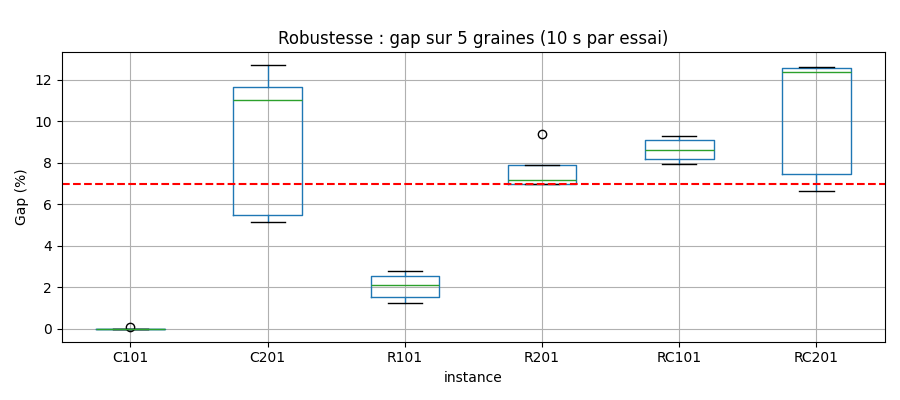

In [ ]:
from IPython.display import Image
Image('resultats/1_robustesse.png')

### 5.2 Convergence (gap en % selon le temps accordé)

| Instance | 2 s | 5 s | 10 s | 30 s |
|---|---|---|---|---|
| C201 | 14.82 | 13.72 | 11.03 | **5.42** |
| R201 | 16.15 | 10.43 | 9.88 | **6.53** |
| RC201 | 18.87 | 12.65 | 12.65 | **8.09** |
| X-n101-k25 | 6.97 | 5.95 | 5.95 | **5.53** |

- **Fenêtres larges : le temps est déterminant**, le gap est divisé par 2 à 3 entre 2 s et 30 s. L'algorithme n'a pas fini de converger à 10 s.
- **CVRP : convergence rapide**, presque tout est gagné en 5 s, ensuite on stagne autour de 5,5 % : c'est la limite de notre voisinage (optimum local).
- Les paliers (5 s = 10 s pour RC201) viennent du multi-start : le meilleur démarrage n'est pas battu entre les deux.

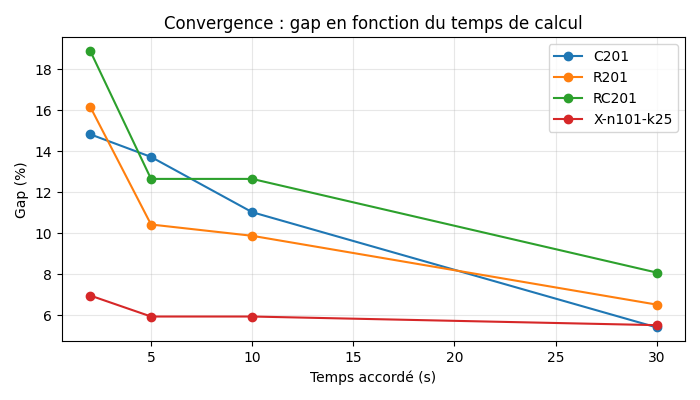

In [ ]:
Image('resultats/2_convergence.png')

### 5.3 Passage à l'échelle (CVRP, 60 s)

| Instance | Clients | Gap (%) | Temps d'une construction GRASP |
|---|---|---|---|
| X-n101-k25 | 100 | 4.43 | 0.02 s |
| X-n200-k36 | 199 | 4.12 | 0.07 s |
| X-n502-k39 | 501 | 4.32 | 0.76 s |
| X-n1001-k43 | 1000 | **37.00** | 4.14 s |

- **Jusqu'à 500 clients, la qualité est stable (≈ 4 %)**.
- **À 1000 clients, le gap explose (37 %)**. Le temps de construction croît environ en **n²** (×2 clients → ×4 environ), et chaque itération tabou ne regarde qu'un échantillon de 25 clients sur 1000 : en 60 s, la recherche n'a pas le temps de corriger la solution de départ.
- **Limite identifiée** : pour plusieurs milliers de clients, il faut restreindre le voisinage aux **k plus proches voisins** de chaque client et accélérer la construction.

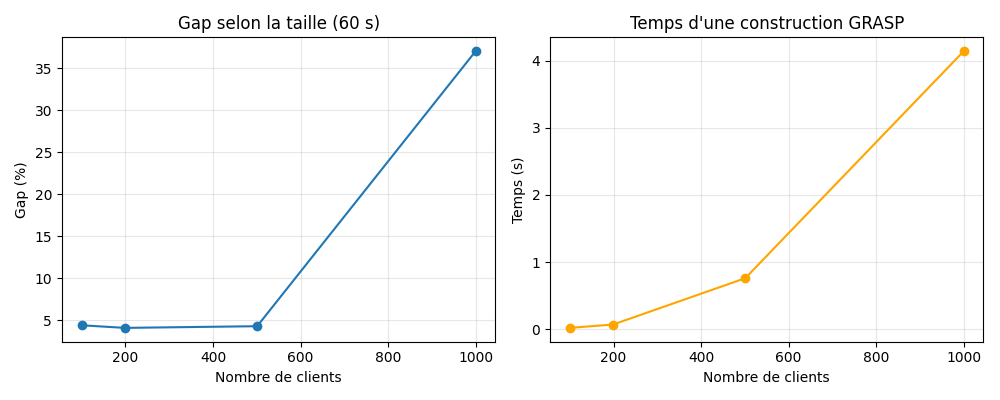

In [ ]:
Image('resultats/3_taille.png')

### 5.4 Sensibilité aux paramètres (gap moyen sur C201, R101, RC201, 10 s, 1 graine)

| alpha | 0.0 | 0.1 | 0.2 (défaut) | 0.4 | 0.7 |
|---|---|---|---|---|---|
| Gap moyen (%) | **3.94** | 4.06 | 8.75 | 7.18 | 11.87 |

| Taille tabou | 3 | 10 (défaut) | 20 | 40 |
|---|---|---|---|---|
| Gap moyen (%) | 7.22 | 8.75 | **6.08** | 9.48 |

- **alpha est le paramètre le plus influent** : une RCL petite (alpha ≤ 0,1, construction presque gloutonne) donne nettement de meilleurs départs. Trop d'aléatoire (0,7) dégrade la qualité. Notre valeur par défaut de 0,2 n'est **pas** la meilleure.
- **La taille tabou a un effet plus faible et irrégulier** ; 20 semble un bon compromis. Une liste trop longue (40) bloque trop de clients.
- ⚠️ Une seule graine par réglage : vu l'écart-type mesuré en 5.1 (jusqu'à 3,6 points), ces tendances sont à confirmer avec plusieurs graines.

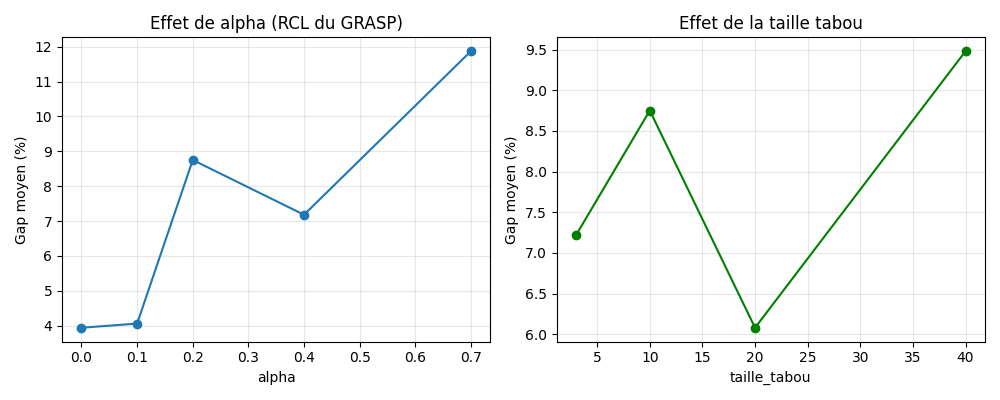

In [ ]:
Image('resultats/4_sensibilite.png')

### 5.5 Bilan de l'étude

| Constat | Conséquence |
|---|---|
| Fenêtres serrées : stable et bon | La méthode est adaptée |
| Fenêtres larges : instable, lent à converger | Donner plus de temps, voisinage plus fort |
| > 500 clients : gap qui explose | Voisinage aux k plus proches voisins, construction plus rapide |
| alpha = 0,2 n'est pas optimal | Passer à alpha ≈ 0,1 et refaire le benchmark |

**Remarque sur la reproductibilité.** Nous avons relancé la même étude sur un deuxième ordinateur, avec les mêmes graines. Les chiffres ne sont pas identiques :

| Mesure | PC 1 | PC 2 |
|---|---|---|
| C201, moyenne sur 5 graines | 9.20 % | 4.71 % |
| RC101, moyenne sur 5 graines | 8.63 % | 7.69 % |
| X-n1001-k43 (60 s) | 37.00 % | 34.59 % |
| Meilleur alpha | 0.0 (3.94 %) | 0.1 (2.64 %) |

L'arrêt se fait au **temps** et non au nombre d'itérations : une machine plus rapide fait plus d'itérations dans le même temps, donc la graine ne suffit pas à reproduire le résultat. Les **conclusions restent les mêmes** sur les deux machines (fenêtres serrées stables, fenêtres larges instables, explosion à 1000 clients, alpha petit meilleur). Pour une comparaison exactement reproductible, il faudrait fixer un nombre d'itérations au lieu d'un temps.

*Un gap de « -0.00 % » signifie qu'on a retrouvé la BKS (petit écart d'arrondi des flottants).*

## 6. Amélioration 1 : réglage de alpha (0,2 → 0,1)

L'étude de sensibilité (5.4) montrait, sur nos deux machines, qu'un **alpha petit** donne de meilleurs résultats. On change donc la valeur par défaut dans `benchmark_vrplib.py` :
```python
# avant
def tester(nom, graine=0, temps_max=20, alpha=0.2, taille_tabou=10,
# maintenant
def tester(nom, graine=0, temps_max=20, alpha=0.1, taille_tabou=10,
```
Avec alpha = 0,1, la RCL ne garde que les candidats très proches du meilleur : la construction est presque gloutonne (plus proche voisin), avec juste assez d'aléatoire pour que le multi-start explore des solutions différentes.

On relance le benchmark complet (20 instances, 20 s, graine 0). Les anciens résultats sont gardés dans `resultats_20s_alpha02.csv`.

| Instance | Gap alpha = 0,2 | Gap alpha = 0,1 |
|---|---|---|
| C101 | 0.00 | 0.00 |
| C102 | 0.00 | 0.11 |
| C105 | 0.00 | 0.00 |
| C201 | 5.42 | **0.00** |
| C202 | 5.98 | **0.00** |
| C205 | 0.00 | 0.00 |
| R101 | 1.47 | 1.76 |
| R102 | 3.68 | 2.15 |
| R105 | 6.57 | 2.88 |
| R201 | 7.16 | 4.83 |
| R202 | 3.68 | 5.78 |
| R205 | 9.31 | 8.74 |
| RC101 | 5.22 | 3.27 |
| RC102 | 3.73 | 6.67 |
| RC105 | 5.66 | 5.32 |
| RC201 | 8.09 | 5.08 |
| RC202 | 12.09 | **3.81** |
| RC205 | 11.05 | 6.63 |
| X-n101-k25 | 4.43 | 5.60 |
| X-n110-k13 | 6.06 | 4.18 |

| Famille | C1 | C2 | R1 | R2 | RC1 | RC2 | X | **Global** |
|---|---|---|---|---|---|---|---|---|
| alpha = 0,2 | 0.00 | 3.80 | 3.91 | 6.72 | 4.87 | 10.41 | 5.24 | **4.98** |
| alpha = 0,1 | 0.04 | 0.00 | 2.26 | 6.45 | 5.09 | 5.17 | 4.89 | **3.34** |

**Analyse :**
- **Gap moyen : 4,98 % → 3,34 %**, et **19 instances sur 20 sous 7 %** (contre 15 avant). Seule R205 reste au-dessus (8,74 %).
- **Gros gain sur les fenêtres larges** : RC2 passe de 10,4 % à 5,2 %, et la BKS est retrouvée sur C201 et C202. Avec des fenêtres larges, une bonne construction de départ compte beaucoup (cf. 5.1).
- Quelques instances se dégradent un peu (R202, RC102, X-n101). Avec un seul lancement par instance, ces écarts restent dans la dispersion mesurée en 5.1 : c'est la **moyenne** qui compte.
- Toutes les solutions sont valides.

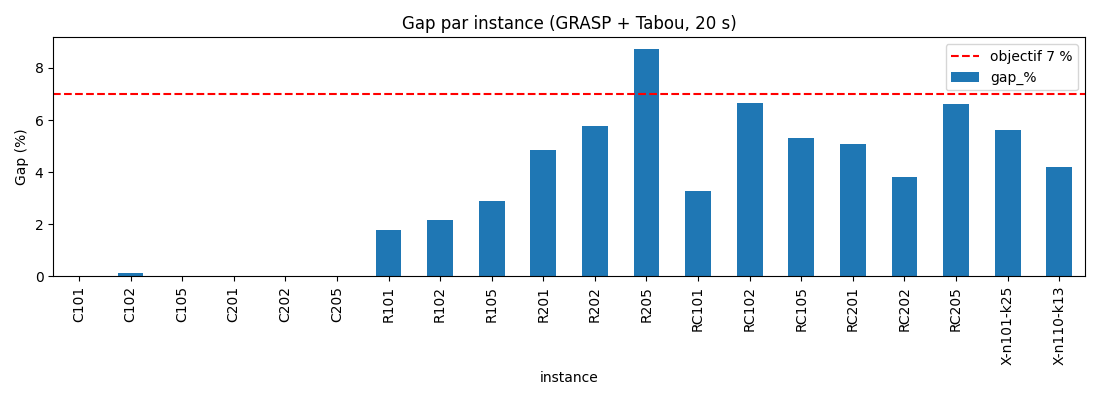

In [ ]:
Image('gap_par_instance_20s.png')